In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose


# Thiết lập cấu hình hiển thị biểu đồ tiếng Việt và giao diện
sns.set_theme(style="whitegrid")
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (14, 6)

# Kết nối PostgreSQL lấy dữ liệu Master Feature Store đã hợp nhất
DB_USER = "postgres"
DB_PASSWORD = "0101"
DB_HOST = "localhost"
DB_PORT = "5432"
DB_NAME = "coffee_db"

DATABASE_URL = f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
engine = create_engine(DATABASE_URL)

df_eda = pd.read_sql("SELECT * FROM coffee_master_feature_store ORDER BY \"Date\" ASC;", engine)
df_eda['Date'] = pd.to_datetime(df_eda['Date'])

print(f"[+] Đã tải thành công {len(df_eda)} dòng và {len(df_eda.columns)} cột từ bảng 'coffee_master_feature_store'.")
display(df_eda.head(3))

[+] Đã tải thành công 2027 dòng và 202 cột từ bảng 'coffee_master_feature_store'.


,Date,Price_DakLak,Price_DakNong,Price_GiaLai,Price_LamDong,Temp_Average,Temp_Min,Temp_Max,Precipitation,Wind_Speed,...,Price_DakNong_Diff_1d,Price_DakNong_PctChange_1d,Price_GiaLai_Diff_1d,Price_GiaLai_PctChange_1d,Price_LamDong_Diff_1d,Price_LamDong_PctChange_1d,Robusta_Close_Diff_1d,Robusta_Close_PctChange_1d,Target_Price_7d_Ahead,Target_Price_30d_Ahead
0,2021-02-03,31300.0,31100.0,31100.0,30800.0,20.7,17.4,26.3,0.0,35.1,...,-500.0,-0.015823,-500.0,-0.015823,-500.0,-0.015974,0.549995,0.004457,31700.0,32500.0
1,2021-02-04,31800.0,31600.0,31600.0,31300.0,20.8,17.0,26.2,0.0,34.6,...,500.0,0.016077,500.0,0.016077,500.0,0.016234,0.100006,0.000807,31900.0,32400.0
2,2021-02-05,32100.0,31900.0,31900.0,31500.0,21.3,18.0,27.7,0.0,29.9,...,300.0,0.009494,300.0,0.009494,200.0,0.006390,0.449997,0.003628,31900.0,32400.0


# EDA đơn biến

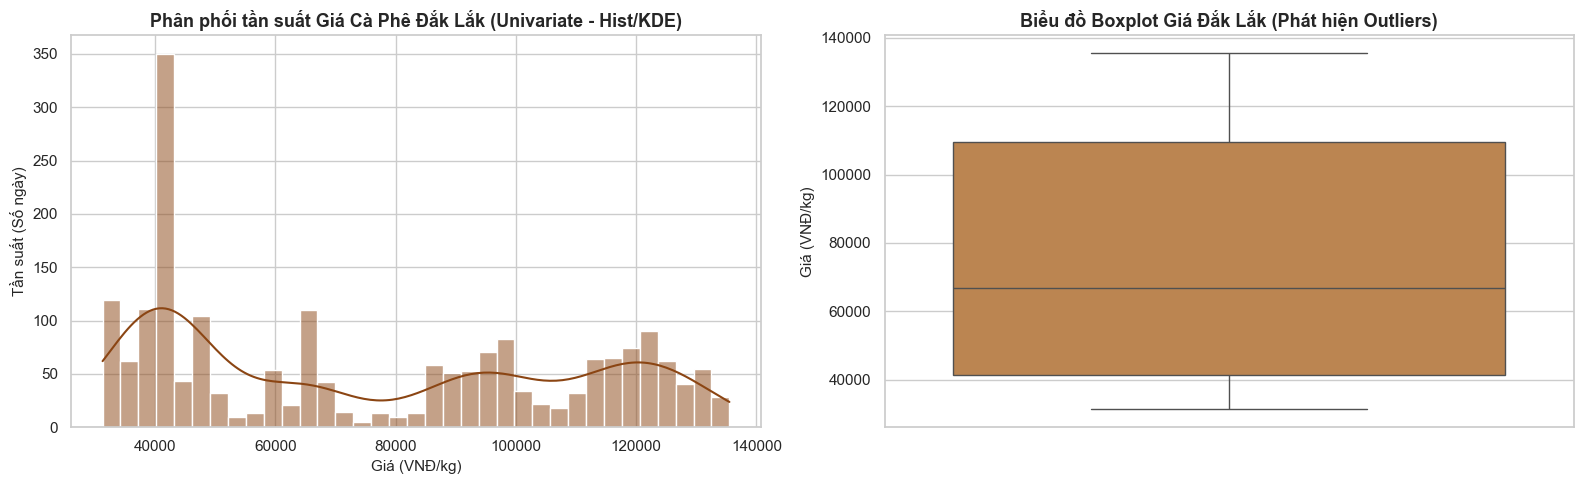


--- THỐNG KÊ MÔ TẢ GIÁ ĐẮK LẮK ---
count      2027.000000
mean      75393.389245
std       33835.875657
min       31300.000000
25%       41500.000000
50%       66700.000000
75%      109500.000000
max      135500.000000
Name: Price_DakLak, dtype: float64


In [3]:
# Phân tích phân phối tần suất và kiểm tra giá trị ngoại lai của biến mục tiêu (Giá Đắk Lắk)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Biểu đồ Histogram kết hợp đường cong mật độ (KDE)
sns.histplot(df_eda['Price_DakLak'], kde=True, ax=axes[0], color='saddlebrown', bins=35)
axes[0].set_title('Phân phối tần suất Giá Cà Phê Đắk Lắk (Univariate - Hist/KDE)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Giá (VNĐ/kg)', fontsize=11)
axes[0].set_ylabel('Tần suất (Số ngày)', fontsize=11)

# Biểu đồ Boxplot nhận diện biên độ và các điểm dị thường (Outliers)
sns.boxplot(y=df_eda['Price_DakLak'], ax=axes[1], color='peru')
axes[1].set_title('Biểu đồ Boxplot Giá Đắk Lắk (Phát hiện Outliers)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Giá (VNĐ/kg)', fontsize=11)

plt.tight_layout()
plt.show()

# Thống kê mô tả nhanh phân phối giá
print("\n--- THỐNG KÊ MÔ TẢ GIÁ ĐẮK LẮK ---")
print(df_eda['Price_DakLak'].describe())

# EDA đa biến

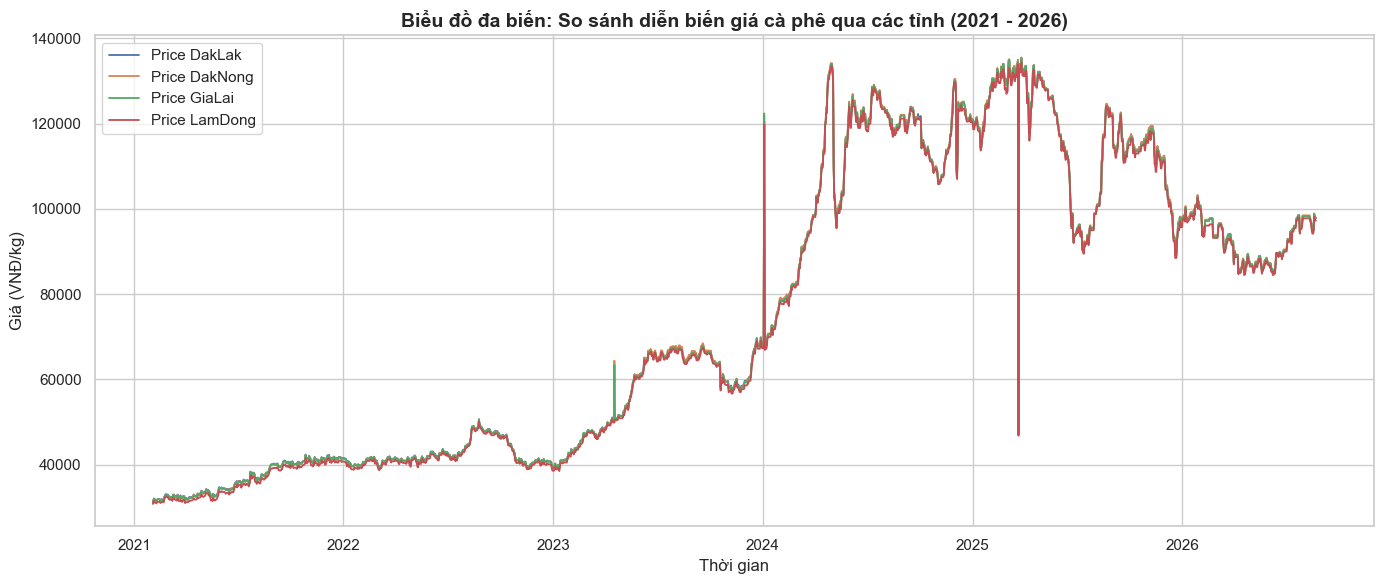

In [4]:
# Khám phá mối quan hệ đồng pha về giá giữa các tỉnh trọng điểm qua thời gian
plt.figure(figsize=(14, 6))

province_cols = ['Price_DakLak', 'Price_DakNong', 'Price_GiaLai', 'Price_LamDong']
for col in province_cols:
    if col in df_eda.columns:
        plt.plot(df_eda['Date'], df_eda[col], label=col.replace('_', ' '), linewidth=1.3)

plt.title('Biểu đồ đa biến: So sánh diễn biến giá cà phê qua các tỉnh (2021 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Thời gian', fontsize=12)
plt.ylabel('Giá (VNĐ/kg)', fontsize=12)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

# Tương quan

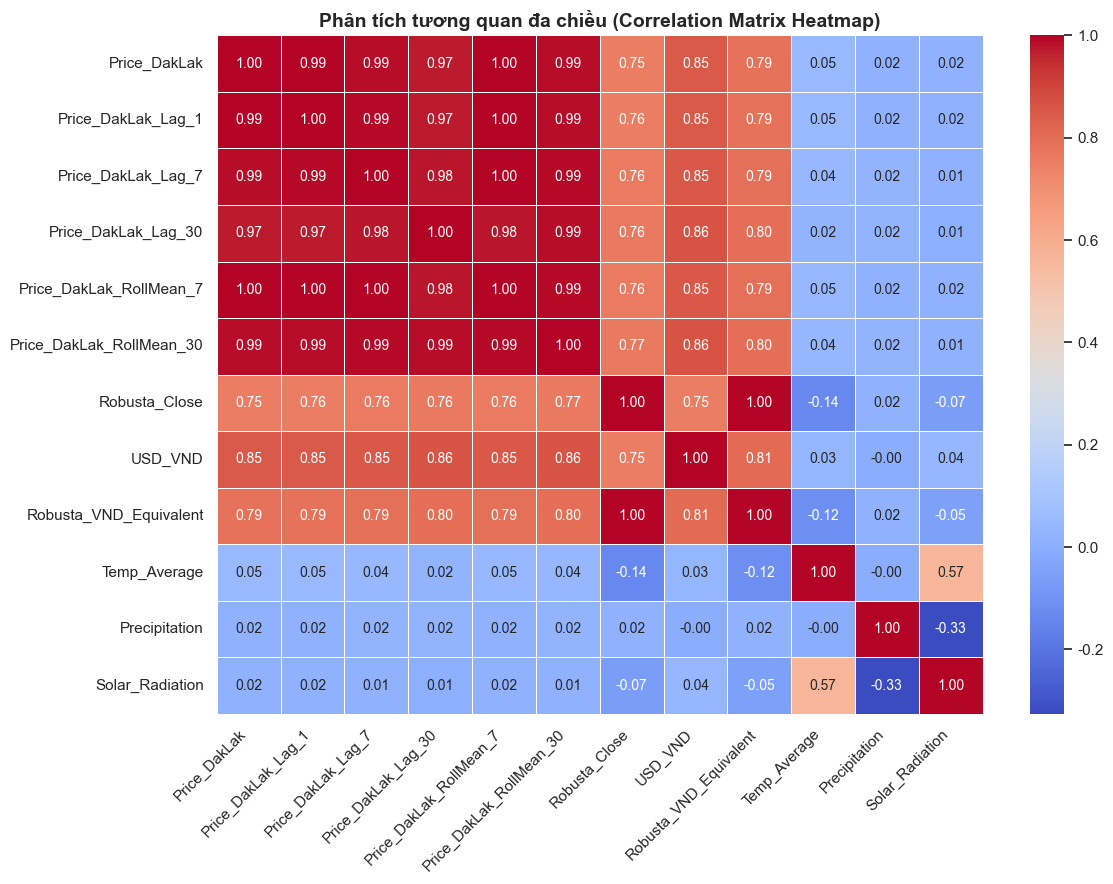

In [5]:
# Phân tích ma trận tương quan đa chiều giữa biến mục tiêu với các đặc trưng trễ, vĩ mô và thời tiết
plt.figure(figsize=(12, 9))

corr_features = [
    'Price_DakLak', 'Price_DakLak_Lag_1', 'Price_DakLak_Lag_7', 'Price_DakLak_Lag_30',
    'Price_DakLak_RollMean_7', 'Price_DakLak_RollMean_30',
    'Robusta_Close', 'USD_VND', 'Robusta_VND_Equivalent',
    'Temp_Average', 'Precipitation', 'Solar_Radiation'
]

valid_corr_cols = [c for c in corr_features if c in df_eda.columns]
matrix_corr = df_eda[valid_corr_cols].corr()

sns.heatmap(matrix_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.6, cbar=True, annot_kws={"size": 10})
plt.title('Phân tích tương quan đa chiều (Correlation Matrix Heatmap)', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Phân rã chuỗi thời gian chuyên sâu

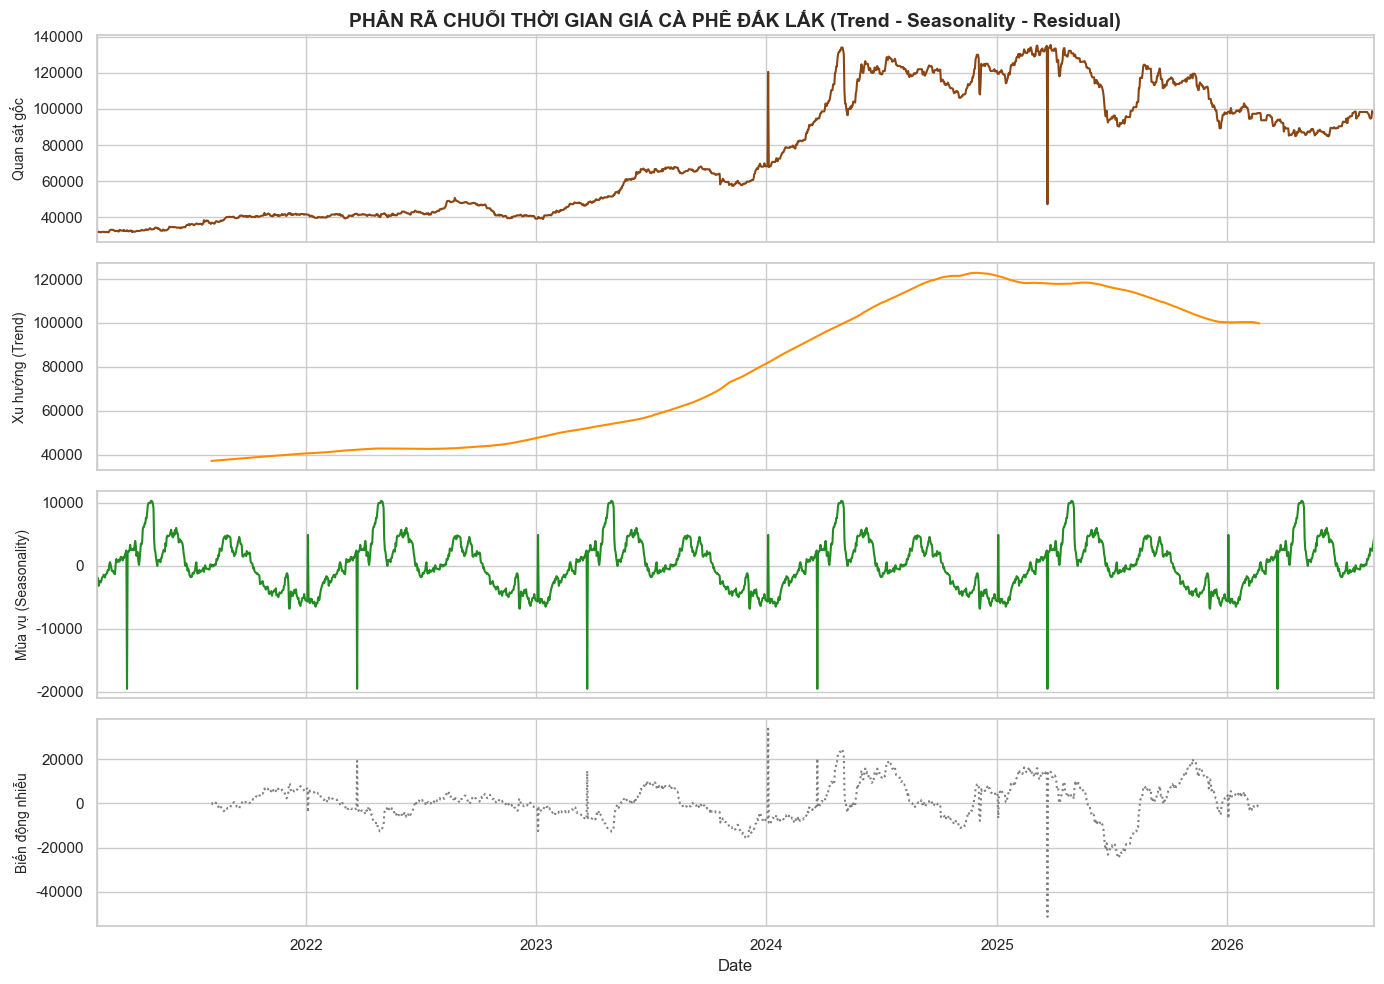

In [6]:
# Đặt cột Date làm Index để phục vụ phân rã chuỗi thời gian
df_decomp = df_eda.set_index('Date')

# Thực hiện phân rã chuỗi thời gian với chu kỳ mùa vụ 365 ngày
decomposition = seasonal_decompose(df_decomp['Price_DakLak'].dropna(), model='additive', period=365)

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

decomposition.observed.plot(ax=ax1, color='saddlebrown')
ax1.set_ylabel('Quan sát gốc', fontsize=10)
ax1.set_title('PHÂN RÃ CHUỖI THỜI GIAN GIÁ CÀ PHÊ ĐẮK LẮK (Trend - Seasonality - Residual)', fontsize=14, fontweight='bold')

decomposition.trend.plot(ax=ax2, color='darkorange')
ax2.set_ylabel('Xu hướng (Trend)', fontsize=10)

decomposition.seasonal.plot(ax=ax3, color='forestgreen')
ax3.set_ylabel('Mùa vụ (Seasonality)', fontsize=10)

decomposition.resid.plot(ax=ax4, color='gray', linestyle='dotted')
ax4.set_ylabel('Biến động nhiễu', fontsize=10)

plt.tight_layout()
plt.show()

# Biểu đồ tự tương quan ACF & PACF

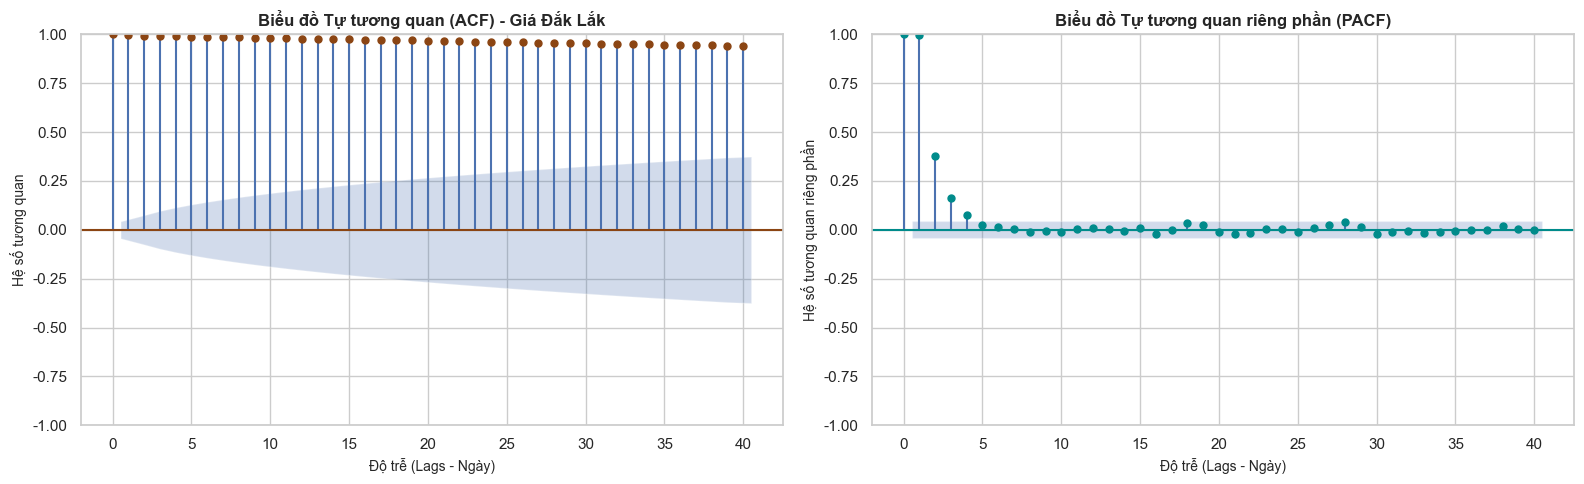

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Biểu đồ Tự tương quan (ACF)
plot_acf(df_eda['Price_DakLak'].dropna(), lags=40, ax=ax1, color='saddlebrown')
ax1.set_title('Biểu đồ Tự tương quan (ACF) - Giá Đắk Lắk', fontsize=12, fontweight='bold')
ax1.set_xlabel('Độ trễ (Lags - Ngày)', fontsize=10)
ax1.set_ylabel('Hệ số tương quan', fontsize=10)

# Biểu đồ Tự tương quan riêng phần (PACF)
plot_pacf(df_eda['Price_DakLak'].dropna(), lags=40, ax=ax2, method='ywm', color='darkcyan')
ax2.set_title('Biểu đồ Tự tương quan riêng phần (PACF)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Độ trễ (Lags - Ngày)', fontsize=10)
ax2.set_ylabel('Hệ số tương quan riêng phần', fontsize=10)

plt.tight_layout()
plt.show()